# Rajuk Image Level Classifier — Bare Neural Network (MLP)

**Architecture:** Fully-connected Multi-Layer Perceptron (MLP) only.
No convolutions, no pretrained weights, no feature extractors.

**Input:** Raw flattened pixel values → 128×128×3 = **49,152 features per image**

**Pipeline:**
1. Local Setup (no Google Drive needed)
2. Configuration
3. Load Labels
4. Collect Paths & Leakage-Free Split
5. Sample Image Preview
6. Dataset (flatten pixels → MLP input)
7. DataLoaders
8. MLP Architecture
9. Weighted Loss & Helpers
10. K-Fold Cross-Validation
11. Fine-tune & Evaluate
12. Classification Report & Confusion Matrix
13. Learning Curves (Train / Val / Test error by dataset size)
14. Full Training History
15. Save Model
16. Sanity Check

## 1. Local Setup (no Google Drive needed)

This notebook runs **locally on your NVIDIA GPU**. Images are read directly from
the project folders on disk — no Colab / Drive mount required.

In [29]:
# Running locally — no Google Drive mount needed.
# Image folders are read straight from disk (paths set in the Configuration cell).
print('Running locally — no Drive mount required.')

Running locally — no Drive mount required.


## 2. Import Libraries

In [30]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 3. Configuration

In [31]:
# ── Paths (LOCAL) ───────────────────────────────────────────────────────────────
# Root folder of the Final Project on this machine.
DRIVE_BASE    = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet.csv'

# Where trained artifacts / plots are written (keep them next to this notebook).
OUTPUT_DIR    = Path.cwd()

# Sanity-check the paths so failures are obvious up front.
for label, pth in [('Augmented dir', AUGMENTED_DIR), ('Real images dir', REAL_DIR)]:
    print(f'  {label:16s}: {pth}  ->  {"OK" if pth.exists() else "MISSING!"}')
if not (XLSX_PATH.exists() or CSV_PATH.exists()):
    print('  WARNING: neither the .xlsx nor the .csv label file was found!')

# ── Image & MLP settings ───────────────────────────────────────────────────────
CLASS_NAMES   = ['negative', 'moderate', 'positive']
ALLOWED_EXTS  = {'.jpg', '.jpeg', '.png', '.bmp'}

# 128x128 → 49,152 input features per image
IMAGE_SIZE    = (128, 128)
INPUT_DIM     = IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3   # 49,152

# ── Hyper-parameters ───────────────────────────────────────────────────────────
BATCH_SIZE    = 32
LR            = 1e-3
NUM_EPOCHS    = 60
KFOLD_SPLITS  = 5
PATIENCE      = 10
WEIGHT_DECAY  = 1e-3
DROPOUT       = 0.4

# ── Split fractions (applied to unique REAL subject IDs) ──────────────────────
# Same leakage-free scheme as the improved CNN notebook: each subject's augmented
# copies follow it into whichever split (train / val / test) the subject lands in.
#   TEST_FRACTION = 0.10  |  VAL_FRACTION = 0.18  →  ~72 / 18 / 10 split
TEST_FRACTION = 0.10
VAL_FRACTION  = 0.18

# ── Learning-curve steps ───────────────────────────────────────────────────────
DATASET_STEPS = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

print('Configuration loaded.')
print(f'  Image size    : {IMAGE_SIZE}')
print(f'  Input dim     : {INPUT_DIM:,} features per image')
print(f'  Batch size    : {BATCH_SIZE}')
print(f'  Epochs        : {NUM_EPOCHS}')
print(f'  Val fraction  : {VAL_FRACTION}  |  Test fraction : {TEST_FRACTION}')

  Augmented dir   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Augmented_raw_data  ->  OK
  Real images dir : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\raw_data\final train image  ->  OK
Configuration loaded.
  Image size    : (128, 128)
  Input dim     : 49,152 features per image
  Batch size    : 32
  Epochs        : 60
  Val fraction  : 0.18  |  Test fraction : 0.1


## 4. Load Labels

In [32]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(df, target):
    for col in df.columns:
        if normalize_header(col) == target:
            return col
    return None

def normalize_level(value):
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    mapping = {'p': 'positive', 'positive': 'positive',
               'm': 'moderate',  'moderate': 'moderate',
               'n': 'negative',  'negative': 'negative'}
    return mapping.get(text)

def load_label_mapping(df, level_col, class_names):
    label_lookup = {name: idx for idx, name in enumerate(class_names)}
    label_map = {}
    for row_index, value in enumerate(df[level_col].tolist(), start=1):
        normalized = normalize_level(value)
        if normalized is None:
            continue
        label_map[row_index] = label_lookup[normalized]
    return label_map

if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(f'No dataset file found at {DRIVE_BASE}.')

level_col = (
    find_column(df, 'levelpositivemoderatenegative')
    or find_column(df, 'level')
)
if level_col is None:
    raise ValueError('Level column not found.')

label_map = load_label_mapping(df, level_col, CLASS_NAMES)
print(f'Loaded {len(df):,} rows | {len(label_map):,} valid labels | source: {source_path.name}')

Loaded 372 rows | 372 valid labels | source: Real ML_DataSet.csv


## 5. Collect Image Paths & Leakage-Free Split

Split is done by **unique subject ID** (real images only) so that no subject's
augmented copy can appear across split boundaries. Each subject's augmented copies
**follow it** into whichever split (train / val / test) the subject lands in —
exactly the scheme used by the improved CNN notebook, giving an even
~72 / 18 / 10 distribution across train / val / test.

In [33]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.lower())
    return int(match.group(1)) if match else None

def collect_all_raw(base_dir, label_map):
    paths, labels = [], []
    skip_idx = skip_lbl = 0
    if not base_dir.exists():
        return paths, labels, skip_idx, skip_lbl
    for p in base_dir.rglob('*'):
        if not (p.is_file() and p.suffix.lower() in ALLOWED_EXTS):
            continue
        idx = parse_image_index(p.stem.strip())
        if idx is None:
            skip_idx += 1; continue
        lbl = label_map.get(idx)
        if lbl is None:
            skip_lbl += 1; continue
        paths.append(p)
        labels.append(lbl)
    return paths, labels, skip_idx, skip_lbl

aug_paths,  aug_labels,  si_a, sl_a = collect_all_raw(AUGMENTED_DIR, label_map)
real_paths, real_labels, si_r, sl_r = collect_all_raw(REAL_DIR,      label_map)

print(f'Augmented images         : {len(aug_paths):,}')
print(f'Real images              : {len(real_paths):,}')
print(f'Skipped (no index)       : {si_a + si_r}')
print(f'Skipped (no label match) : {sl_a + sl_r}')

# ── Leakage-free split by unique subject ID ────────────────────────────────────
unique_indices     = sorted(set(
    parse_image_index(p.stem.strip()) for p in real_paths
    if parse_image_index(p.stem.strip()) is not None
))
unique_labels_list = [label_map[i] for i in unique_indices]
all_uq             = np.arange(len(unique_indices))

trainval_uq, test_uq = train_test_split(
    all_uq, test_size=TEST_FRACTION, random_state=SEED, stratify=unique_labels_list
)
val_rel = VAL_FRACTION / (1.0 - TEST_FRACTION)
train_uq, val_uq = train_test_split(
    trainval_uq, test_size=val_rel, random_state=SEED,
    stratify=np.array(unique_labels_list)[trainval_uq]
)

train_img_ids = set(np.array(unique_indices)[train_uq])
val_img_ids   = set(np.array(unique_indices)[val_uq])
test_img_ids  = set(np.array(unique_indices)[test_uq])

train_paths_final, train_labels_final = [], []
val_paths_final,   val_labels_final   = [], []
test_paths_final,  test_labels_final  = [], []

# Augmented → each subject's aug copies follow it into its split
for p, lbl in zip(aug_paths, aug_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

# Real → correct split
for p, lbl in zip(real_paths, real_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

N_total = len(train_paths_final) + len(val_paths_final) + len(test_paths_final)
print(f'\nLeakage-free split:')
print(f'  Train (real + aug) : {len(train_paths_final):,}  ({100*len(train_paths_final)/N_total:.1f} %)')
print(f'  Val   (real + aug) : {len(val_paths_final):,}  ({100*len(val_paths_final)/N_total:.1f} %)')
print(f'  Test  (real + aug) : {len(test_paths_final):,}  ({100*len(test_paths_final)/N_total:.1f} %)')
print(f'  Total accounted    : {N_total:,}  (of {len(aug_paths)+len(real_paths):,} raw — diff = {len(aug_paths)+len(real_paths)-N_total} skipped)')

val_counts  = np.bincount(val_labels_final,  minlength=len(CLASS_NAMES))
test_counts = np.bincount(test_labels_final, minlength=len(CLASS_NAMES))
print('\nValidation-set class distribution:')
for name, cnt in zip(CLASS_NAMES, val_counts):
    print(f'  {name:10s}: {cnt:,}')
print('\nTest-set class distribution:')
for name, cnt in zip(CLASS_NAMES, test_counts):
    print(f'  {name:10s}: {cnt:,}')

counts = np.bincount(train_labels_final + val_labels_final + test_labels_final,
                     minlength=len(CLASS_NAMES))
print('\nClass distribution (total):')
for name, cnt in zip(CLASS_NAMES, counts):
    print(f'  {name:10s}: {cnt:,}')

Augmented images         : 5,968
Real images              : 373
Skipped (no index)       : 0
Skipped (no label match) : 17

Leakage-free split:
  Train (real + aug) : 4,556  (71.8 %)
  Val   (real + aug) : 1,139  (18.0 %)
  Test  (real + aug) : 646  (10.2 %)
  Total accounted    : 6,341  (of 6,341 raw — diff = 0 skipped)

Validation-set class distribution:
  negative  : 697
  moderate  : 255
  positive  : 187

Test-set class distribution:
  negative  : 408
  moderate  : 136
  positive  : 102

Class distribution (total):
  negative  : 3,910
  moderate  : 1,394
  positive  : 1,037


## 6. 📷 Sample Images — Data Preview

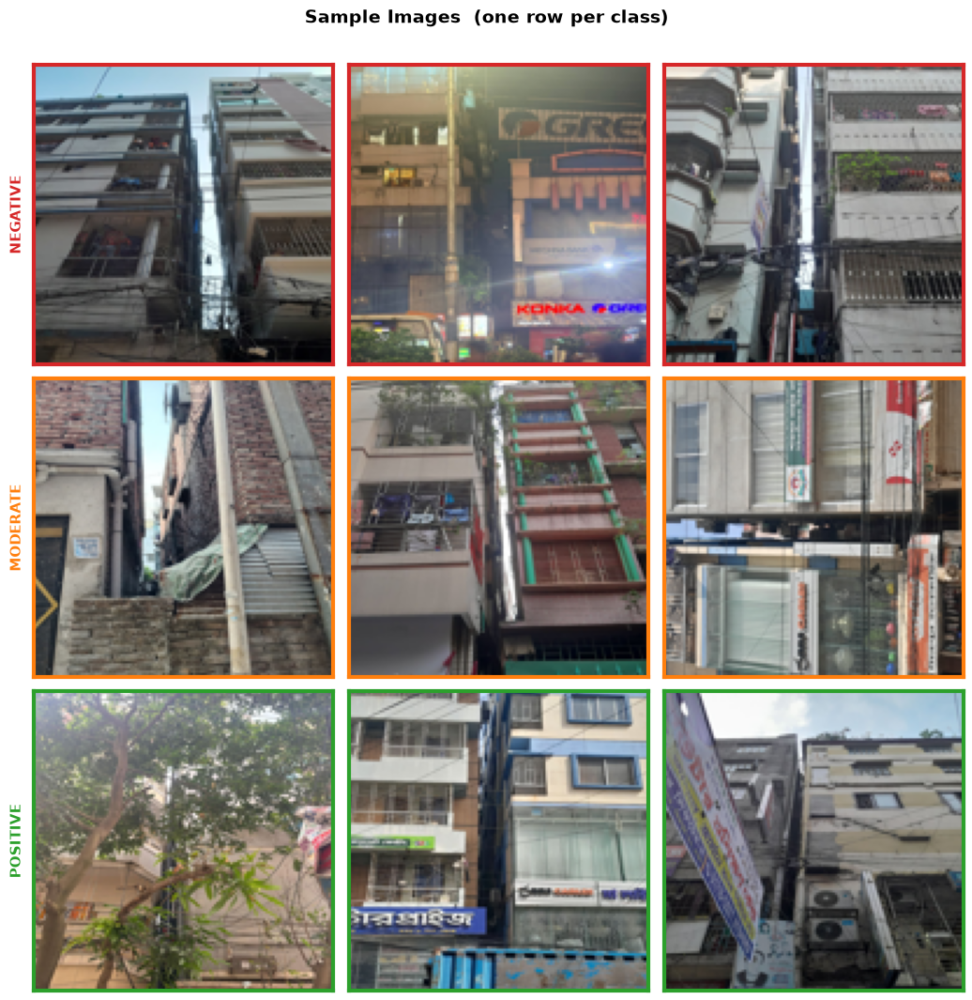

Sample images displayed.


In [34]:
SAMPLES_PER_CLASS = 3
label_to_real_paths = {i: [] for i in range(len(CLASS_NAMES))}
for p, lbl in zip(real_paths, real_labels):
    label_to_real_paths[lbl].append(p)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    len(CLASS_NAMES), SAMPLES_PER_CLASS,
    figsize=(SAMPLES_PER_CLASS * 3.5, len(CLASS_NAMES) * 3.5)
)
fig.suptitle('Sample Images  (one row per class)', fontsize=14, fontweight='bold', y=1.01)
border_colours = ['#d62728', '#ff7f0e', '#2ca02c']

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    candidates = label_to_real_paths[cls_idx]
    chosen = rng.choice(len(candidates),
                        size=min(SAMPLES_PER_CLASS, len(candidates)),
                        replace=False)
    for col, path_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        img = Image.open(candidates[path_idx]).convert('RGB').resize(IMAGE_SIZE)
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_colours[cls_idx])
            spine.set_linewidth(3)
        if col == 0:
            ax.set_ylabel(cls_name.upper(), fontsize=11, fontweight='bold',
                          color=border_colours[cls_idx], rotation=90, labelpad=8)

plt.tight_layout()
try:
    plt.savefig(OUTPUT_DIR / 'sample_images.png', dpi=120, bbox_inches='tight')
except OSError as e:
    print(f'  (could not save figure — {e})')
plt.show()
print('Sample images displayed.')

## 7. Dataset — Flatten Pixels into MLP Input

An MLP takes a **1D vector** as input. Each image is:
- Resized to 128×128
- Normalised to [0, 1]
- Flattened: 128 × 128 × 3 = **49,152 features**

For the training set, we apply **random flips and slight brightness jitter** before
flattening to add diversity. Val/test are flattened as-is.

In [35]:
import random
from PIL import ImageEnhance, ImageOps


def augment_pil(img: Image.Image) -> Image.Image:
    """Lightweight augmentation for MLP — purely pixel-level, no spatial ops."""
    if random.random() < 0.5:
        img = ImageOps.mirror(img)                          # horizontal flip
    if random.random() < 0.3:
        img = ImageOps.flip(img)                            # vertical flip
    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        img = ImageEnhance.Brightness(img).enhance(factor)  # brightness jitter
    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        img = ImageEnhance.Contrast(img).enhance(factor)    # contrast jitter
    if random.random() < 0.3:
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Color(img).enhance(factor)       # saturation jitter
    return img


def pil_to_flat_tensor(img: Image.Image) -> torch.Tensor:
    """Convert PIL image → normalised float32 tensor of shape (INPUT_DIM,)."""
    arr = np.asarray(img.resize(IMAGE_SIZE), dtype=np.float32) / 255.0
    return torch.from_numpy(arr.flatten())   # (49152,)


class RajukFlatDataset(Dataset):
    """
    MLP dataset — stores PIL images in RAM (uint8) and converts to flat
    float32 tensors on the fly in __getitem__.

    If augment=True (training set), random flips/brightness applied per call
    so every epoch sees slightly different pixel values.
    """

    def __init__(self, image_paths, labels, augment: bool = False):
        self.labels  = labels
        self.augment = augment
        n = len(image_paths)
        ram_mb = n * IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3 / 1e6
        print(f'  Caching {n:,} PIL images … (est. {ram_mb:.0f} MB RAM)')
        self.images = []
        for p in image_paths:
            with Image.open(p) as img:
                self.images.append(img.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR))
        print(f'  Done. augment={augment}')

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.augment:
            img = augment_pil(img)
        return pil_to_flat_tensor(img), self.labels[idx]


if len(train_paths_final) == 0:
    raise ValueError('No labeled images found. Check folder paths and label mapping.')

print('Building datasets:')
train_dataset = RajukFlatDataset(train_paths_final, train_labels_final, augment=True)
val_dataset   = RajukFlatDataset(val_paths_final,   val_labels_final,   augment=False)
test_dataset  = RajukFlatDataset(test_paths_final,  test_labels_final,  augment=False)

total_mb = (len(train_dataset)+len(val_dataset)+len(test_dataset)) * IMAGE_SIZE[0]*IMAGE_SIZE[1]*3 / 1e6
print(f'\nTrain: {len(train_dataset):,}  Val: {len(val_dataset):,}  Test: {len(test_dataset):,}')
print(f'Total image RAM: ~{total_mb:.0f} MB')

# Quick shape check
x0, y0 = train_dataset[0]
print(f'\nSample tensor shape : {x0.shape}  (should be ({INPUT_DIM},))')
print(f'Sample label        : {y0}  ({CLASS_NAMES[y0]})')

Building datasets:
  Caching 4,556 PIL images … (est. 224 MB RAM)
  Done. augment=True
  Caching 1,139 PIL images … (est. 56 MB RAM)
  Done. augment=False
  Caching 646 PIL images … (est. 32 MB RAM)
  Done. augment=False

Train: 4,556  Val: 1,139  Test: 646
Total image RAM: ~312 MB

Sample tensor shape : torch.Size([49152])  (should be (49152,))
Sample label        : 1  (moderate)


## 8. DataLoaders

In [36]:
pin = torch.cuda.is_available()
# On Windows + Jupyter, DataLoader worker processes (num_workers>0) frequently hang
# because the in-RAM PIL cache must be pickled to each spawned worker. The images are
# already cached in memory, so workers add little benefit — use 0 for reliability.
NW  = 0

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NW, pin_memory=pin)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)

print(f'Train : {len(train_dataset):,} samples  ({len(train_loader)} batches)')
print(f'Val   : {len(val_dataset):,} samples  ({len(val_loader)} batches)')
print(f'Test  : {len(test_dataset):,} samples  ({len(test_loader)} batches)')

Train : 4,556 samples  (143 batches)
Val   : 1,139 samples  (36 batches)
Test  : 646 samples  (21 batches)


## 9. MLP Architecture

A pure **Multi-Layer Perceptron** — only `nn.Linear`, `nn.BatchNorm1d`,
`nn.ReLU`, and `nn.Dropout` layers. Zero convolutions.

```
Input  :  49,152  (128×128×3 flattened pixels)
  └─ Linear(49152 → 2048) + BN + ReLU + Dropout
  └─ Linear(2048  → 1024) + BN + ReLU + Dropout
  └─ Linear(1024  →  512) + BN + ReLU + Dropout
  └─ Linear(512   →  256) + BN + ReLU + Dropout
  └─ Linear(256   →    3) — raw logits
Output :  3 class logits
```

In [37]:
class RajukMLP(nn.Module):
    """
    Bare Multi-Layer Perceptron for image classification.
    Input: flat pixel vector of length input_dim (49,152 for 128x128 RGB).
    No convolutions, no attention, no pretrained weights.
    """

    def __init__(self, input_dim: int, num_classes: int, dropout: float = 0.4):
        super().__init__()

        def block(in_f, out_f):
            return nn.Sequential(
                nn.Linear(in_f, out_f),
                nn.BatchNorm1d(out_f),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            )

        self.net = nn.Sequential(
            block(input_dim, 2048),
            block(2048,      1024),
            block(1024,       512),
            block(512,        256),
            nn.Linear(256, num_classes),   # output logits — no activation
        )

    def forward(self, x):
        return self.net(x)


_tmp = RajukMLP(INPUT_DIM, len(CLASS_NAMES))
total_params = sum(p.numel() for p in _tmp.parameters())
print(f'MLP total parameters: {total_params:,}')
print('Layers:')
for name, mod in _tmp.named_modules():
    if isinstance(mod, nn.Linear):
        print(f'  {name:30s} {mod}')
del _tmp

MLP total parameters: 103,428,099
Layers:
  net.0.0                        Linear(in_features=49152, out_features=2048, bias=True)
  net.1.0                        Linear(in_features=2048, out_features=1024, bias=True)
  net.2.0                        Linear(in_features=1024, out_features=512, bias=True)
  net.3.0                        Linear(in_features=512, out_features=256, bias=True)
  net.4                          Linear(in_features=256, out_features=3, bias=True)


## 10. Weighted Loss & Training Helpers

In [38]:
# ── Weighted loss to handle class imbalance ────────────────────────────────────
train_labels_arr = np.array(train_labels_final, dtype=np.int64)
class_counts     = np.bincount(train_labels_arr, minlength=len(CLASS_NAMES))
class_weights    = torch.tensor(1.0 / (class_counts + 1e-6), dtype=torch.float32).to(device)
class_weights   /= class_weights.sum()

criterion = nn.CrossEntropyLoss(weight=class_weights)

print('Class counts & weights in training set:')
for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights.cpu()):
    print(f'  {name:10s}: {cnt:,} samples  →  weight {w:.4f}')


# ── Train / evaluate ──────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = correct = total = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss   = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total      += X.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_true = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss   = criterion(logits, y)
        total_loss += loss.item() * X.size(0)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total   += X.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_true


def make_model():
    m   = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
    opt = optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NUM_EPOCHS, eta_min=1e-6)
    return m, opt, sch


print('\nHelpers defined.')

Class counts & weights in training set:
  negative  : 2,805 samples  →  weight 0.1325
  moderate  : 1,003 samples  →  weight 0.3706
  positive  : 748 samples  →  weight 0.4969

Helpers defined.


## 11. K-Fold Cross-Validation on Real Training Images Only

K-Fold runs on **real training images only** (not augmented copies) so
fold accuracy numbers are honest — no near-duplicate images leaking
across fold boundaries.

In [39]:
# Build a real-only training dataset for K-Fold
real_train_paths  = [p for p in train_paths_final
                     if str(AUGMENTED_DIR).lower() not in str(p).lower()]
real_train_labels = [l for p, l in zip(train_paths_final, train_labels_final)
                     if str(AUGMENTED_DIR).lower() not in str(p).lower()]

print(f'Real training images for K-Fold: {len(real_train_paths):,}')

kfold_dataset   = RajukFlatDataset(real_train_paths, real_train_labels, augment=True)
kfold_labels    = np.array(real_train_labels, dtype=np.int64)
kfold_indices   = np.arange(len(kfold_dataset))

min_cls = np.min(np.bincount(kfold_labels, minlength=len(CLASS_NAMES)))
k       = min(KFOLD_SPLITS, int(min_cls))
kfold   = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)

fold_val_accs     = []
best_global_acc   = -1.0
best_global_state = None

for fold, (tr, va) in enumerate(kfold.split(kfold_indices, kfold_labels)):
    print(f'\n{"─"*58}')
    print(f'  Fold {fold+1}/{k}   |   train={len(tr):,}   val={len(va):,}')
    print(f'{"─"*58}')

    fold_train_loader = DataLoader(
        Subset(kfold_dataset, tr),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )
    fold_val_loader = DataLoader(
        Subset(kfold_dataset, va),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NW, pin_memory=pin
    )

    model, optimizer, scheduler = make_model()
    best_fold_acc   = -1.0
    best_fold_state = None
    patience_ctr    = 0

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, fold_train_loader, optimizer)
        vl_loss, vl_acc, _, _ = evaluate(model, fold_val_loader)
        scheduler.step()

        print(f'  Ep {epoch+1:02d}/{NUM_EPOCHS}  '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.4f}  |  '
              f'Val   Loss={vl_loss:.4f} Acc={vl_acc:.4f}')

        if vl_acc > best_fold_acc:
            best_fold_acc   = vl_acc
            patience_ctr    = 0
            best_fold_state = {k2: v.cpu() for k2, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'  Early stopping at epoch {epoch+1}.')
                break

    fold_val_accs.append(best_fold_acc)
    print(f'  → Fold {fold+1} best val acc: {best_fold_acc:.4f}')

    if best_fold_acc > best_global_acc:
        best_global_acc   = best_fold_acc
        best_global_state = best_fold_state

print(f'\nCross-val accuracies : {[f"{a:.4f}" for a in fold_val_accs]}')
print(f'Mean CV accuracy     : {np.mean(fold_val_accs):.4f} ± {np.std(fold_val_accs):.4f}')

Real training images for K-Fold: 268
  Caching 268 PIL images … (est. 13 MB RAM)
  Done. augment=True

──────────────────────────────────────────────────────────
  Fold 1/5   |   train=214   val=54
──────────────────────────────────────────────────────────
  Ep 01/60  Train Loss=1.2095 Acc=0.3178  |  Val   Loss=1.2620 Acc=0.3333
  Ep 02/60  Train Loss=1.1399 Acc=0.4065  |  Val   Loss=2.1850 Acc=0.2593
  Ep 03/60  Train Loss=1.0541 Acc=0.4813  |  Val   Loss=1.4605 Acc=0.3704
  Ep 04/60  Train Loss=1.0633 Acc=0.4766  |  Val   Loss=1.4526 Acc=0.3333
  Ep 05/60  Train Loss=1.0746 Acc=0.4720  |  Val   Loss=1.4088 Acc=0.3704
  Ep 06/60  Train Loss=1.0256 Acc=0.4860  |  Val   Loss=1.3395 Acc=0.3519
  Ep 07/60  Train Loss=1.1233 Acc=0.4766  |  Val   Loss=1.1221 Acc=0.4815
  Ep 08/60  Train Loss=1.0766 Acc=0.5047  |  Val   Loss=1.2306 Acc=0.3519
  Ep 09/60  Train Loss=1.0654 Acc=0.4813  |  Val   Loss=1.1709 Acc=0.3889
  Ep 10/60  Train Loss=1.0006 Acc=0.5187  |  Val   Loss=1.1285 Acc=0.4074
  E

## 12. Fine-tune Best Model on Full Train Set → Evaluate on Val + Test

In [40]:
final_model = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
final_model.load_state_dict({k: v.to(device) for k, v in best_global_state.items()})

ft_optimizer = optim.AdamW(final_model.parameters(), lr=LR / 5, weight_decay=WEIGHT_DECAY)

print('Fine-tuning on full training split …')
for epoch in range(5):
    t_loss, t_acc = train_one_epoch(final_model, train_loader, ft_optimizer)
    print(f'  FT Epoch {epoch+1}/5  Loss={t_loss:.4f}  Acc={t_acc:.4f}')

val_loss,  val_acc,  val_preds,  val_true  = evaluate(final_model, val_loader)
test_loss, test_acc, test_preds, test_true = evaluate(final_model, test_loader)

print(f'\n{"="*50}')
print(f'  Validation — Loss: {val_loss:.4f}   Acc: {val_acc:.4f}')
print(f'  Test       — Loss: {test_loss:.4f}   Acc: {test_acc:.4f}')
print(f'{"="*50}')

Fine-tuning on full training split …
  FT Epoch 1/5  Loss=0.8352  Acc=0.5992
  FT Epoch 2/5  Loss=0.5015  Acc=0.7774
  FT Epoch 3/5  Loss=0.3027  Acc=0.8769
  FT Epoch 4/5  Loss=0.2314  Acc=0.9061
  FT Epoch 5/5  Loss=0.1796  Acc=0.9289

  Validation — Loss: 1.8600   Acc: 0.5786
  Test       — Loss: 1.9064   Acc: 0.5759


## 13. Classification Report & Confusion Matrix

Test Set — Classification Report
──────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.63      0.84      0.72       408
    moderate       0.22      0.11      0.15       136
    positive       0.45      0.15      0.22       102

    accuracy                           0.58       646
   macro avg       0.43      0.37      0.36       646
weighted avg       0.51      0.58      0.52       646



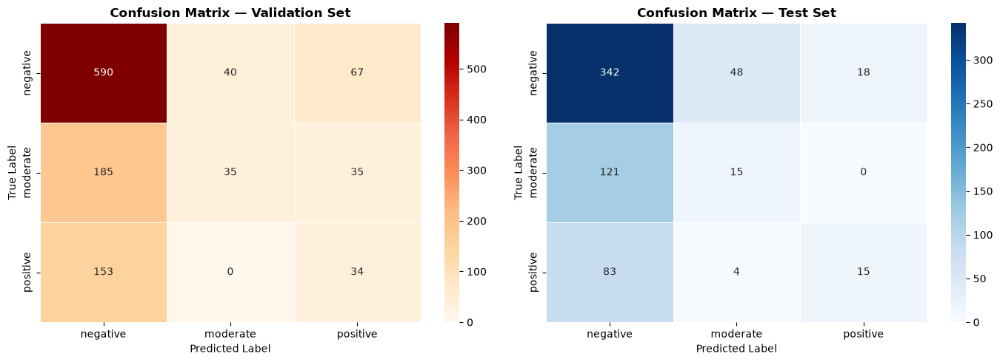

In [41]:
print('Test Set — Classification Report')
print('─' * 50)
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (preds, true, title, cmap) in zip(
    axes,
    [
        (val_preds,  val_true,  'Confusion Matrix — Validation Set', 'OrRd'),
        (test_preds, test_true, 'Confusion Matrix — Test Set',       'Blues'),
    ]
):
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
try:
    plt.savefig(OUTPUT_DIR / 'confusion_matrices.png', dpi=120, bbox_inches='tight')
except OSError as e:
    print(f'  (could not save figure — {e})')
plt.show()

## 13b. Misclassified Validation Examples — Manual Error Analysis

The cells below identify **every misclassified example in the validation set**, export
them to a CSV, and display them as an image grid. Each misclassified example is also
assigned to a group member (~20 per member) so the team can fill in the
*"possible reason for misclassification"* sheet required by the report.

> ⚠️ Run the **fine-tune & evaluate** cell (Section 12) first so `val_preds`,
> `val_true`, and `val_paths_final` are populated.

In [42]:
# ── Identify all misclassified validation images ──────────────────────────────
# val_loader uses shuffle=False → predictions align 1-to-1 with val_paths_final
val_true_arr = np.array(val_true)
val_pred_arr = np.array(val_preds)

assert len(val_paths_final) == len(val_true_arr), \
    'Length mismatch — re-run cell 12 (fine-tune + evaluate) before this cell.'

mis_mask = val_true_arr != val_pred_arr
mis_idx  = np.where(mis_mask)[0]

print(f'Validation set size  : {len(val_true_arr):,}')
print(f'Correctly classified : {int((~mis_mask).sum()):,}')
print(f'Misclassified        : {int(mis_mask.sum()):,}  ({100*mis_mask.mean():.1f} %)')

# Resolve augmented dir once for type detection
aug_dir_resolved = AUGMENTED_DIR.resolve() if AUGMENTED_DIR.exists() else None

N_MEMBERS = 4   # ← change to your actual group size

rows = []
for i in mis_idx:
    path   = val_paths_final[i]
    img_id = parse_image_index(path.stem.strip())
    try:
        is_aug = aug_dir_resolved is not None and \
                 path.resolve().is_relative_to(aug_dir_resolved)
    except Exception:
        is_aug = 'aug' in str(path).lower()
    rows.append({
        'val_index'       : int(i),
        'image_id'        : img_id,
        'file_name'       : path.name,
        'image_type'      : 'augmented' if is_aug else 'real',
        'true_label'      : CLASS_NAMES[val_true_arr[i]],
        'pred_label'      : CLASS_NAMES[val_pred_arr[i]],
        'error_type'      : f'{CLASS_NAMES[val_true_arr[i]]} → {CLASS_NAMES[val_pred_arr[i]]}',
        'file_path'       : str(path),
        'reason_category' : '',   # fill: A=ambiguous B=quality C=occlusion D=lighting E=label_error F=distribution G=imbalance H=other
        'possible_reason' : '',
        'suggested_fix'   : '',
    })

mis_df = pd.DataFrame(rows)

if len(mis_df) > 0:
    per_member = int(np.ceil(len(mis_df) / max(1, N_MEMBERS)))
    mis_df['assigned_member'] = (np.arange(len(mis_df)) // per_member) + 1

# ── Print every misclassified filename ───────────────────────────────────────
print('\n' + '─' * 72)
print(f'  {"#":>4}  {"file_name":<40} {"type":<10}  {"true":>10} → pred')
print('─' * 72)
for rank, row in mis_df.iterrows():
    print(f'  {int(rank)+1:>4}  {row["file_name"]:<40} {row["image_type"]:<10}  '
          f'{row["true_label"]:>10} → {row["pred_label"]}')
print('─' * 72)

print(f'\nError-type breakdown:')
print(mis_df['error_type'].value_counts().to_string())

print(f'\nBreakdown by image type (real vs augmented):')
print(mis_df.groupby(['image_type', 'error_type']).size().rename('count').to_string())

# ── Save CSV ──────────────────────────────────────────────────────────────────
mis_csv = OUTPUT_DIR / 'val_misclassified.csv'
mis_df.to_csv(mis_csv, index=False)
print(f'\nCSV saved → {mis_csv}')
print(f'Columns    : {list(mis_df.columns)}')

mis_df

Validation set size  : 1,139
Correctly classified : 659
Misclassified        : 480  (42.1 %)

────────────────────────────────────────────────────────────────────────
     #  file_name                                type              true → pred
────────────────────────────────────────────────────────────────────────
     1  img100_autocontrast.jpg                  augmented     moderate → negative
     2  img100_brightness_down.jpg               augmented     moderate → negative
     3  img100_brightness_up.jpg                 augmented     moderate → negative
     4  img100_color_down.jpg                    augmented     moderate → negative
     5  img100_color_up.jpg                      augmented     moderate → negative
     6  img100_contrast_down.jpg                 augmented     moderate → negative
     7  img100_contrast_up.jpg                   augmented     moderate → negative
     8  img100_edge_enhance.jpg                  augmented     moderate → negative
     9  img100_eq

,val_index,image_id,file_name,image_type,true_label,pred_label,error_type,file_path,reason_category,possible_reason,suggested_fix,assigned_member
0,0,100,img100_autocontrast.jpg,augmented,moderate,negative,moderate → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
1,1,100,img100_brightness_down.jpg,augmented,moderate,negative,moderate → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
2,2,100,img100_brightness_up.jpg,augmented,moderate,negative,moderate → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
3,3,100,img100_color_down.jpg,augmented,moderate,negative,moderate → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
4,4,100,img100_color_up.jpg,augmented,moderate,negative,moderate → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,1
...,...,...,...,...,...,...,...,...,...,...,...,...
475,1132,231,img231.jpg,real,positive,negative,positive → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4
476,1133,275,img275.jpg,real,positive,negative,positive → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4
477,1134,284,img284.jpg,real,positive,negative,positive → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4
478,1135,285,img285.jpg,real,positive,negative,positive → negative,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,,,,4


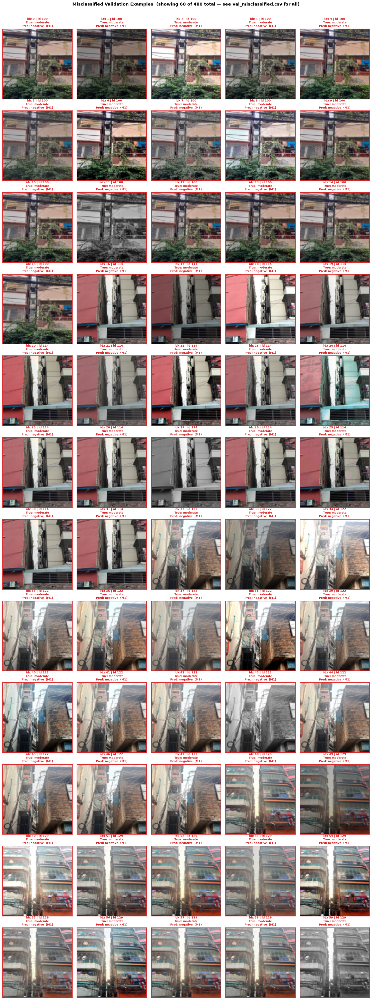

Total misclassified : 480
Displayed           : 60  (first 60)
Full list saved to  : val_misclassified.csv


In [43]:
# ── Visualise misclassified validation images ─────────────────────────────────
# Shows up to MAX_DISPLAY images (all errors go to the CSV; grid is just a preview).
MAX_DISPLAY = 60   # enough for ~4 members × 15 examples each

if len(mis_idx) == 0:
    print('No misclassified validation examples — nothing to display.')
else:
    display_idx = mis_idx[:MAX_DISPLAY]
    n     = len(display_idx)
    cols  = 5
    rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 3.0, rows_ * 3.3))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis('off')

    for j, i in enumerate(display_idx):
        ax  = axes[j]
        img = val_dataset.images[i]
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        ax.axis('on')
        row = mis_df[mis_df['val_index'] == i]
        member = int(row['assigned_member'].iloc[0]) if len(row) > 0 else '?'
        ax.set_title(
            f'idx {i} | id {parse_image_index(val_paths_final[i].stem.strip())}\n'
            f'True: {CLASS_NAMES[val_true_arr[i]]}\n'
            f'Pred: {CLASS_NAMES[val_pred_arr[i]]}  (M{member})',
            fontsize=8, color='#d62728', fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor('#d62728'); spine.set_linewidth(2)

    total_errors = len(mis_idx)
    shown = len(display_idx)
    fig.suptitle(
        f'Misclassified Validation Examples  '
        f'(showing {shown} of {total_errors} total — see val_misclassified.csv for all)',
        fontsize=12, fontweight='bold', y=1.005
    )
    plt.tight_layout()
    try:
        plt.savefig(OUTPUT_DIR / 'val_misclassified.png', dpi=120, bbox_inches='tight')
    except OSError as e:
        print(f'  (could not save figure — {e})')
    plt.show()
    print(f'Total misclassified : {total_errors}')
    print(f'Displayed           : {shown}  (first {MAX_DISPLAY})')
    print(f'Full list saved to  : val_misclassified.csv')

## 14. Learning Curves — Error vs. Dataset Size

| Marker | Meaning |
|--------|---------|
| 🔵 Blue circle | **Training error** |
| 🟠 Orange triangle | **Validation error** |
| 🟢 Green square | **Test error** |

In [44]:
def train_and_measure(n_train: int):
    actual_n = min(n_train, len(train_dataset))
    if actual_n < len(CLASS_NAMES):
        return None

    sub_idx, _ = train_test_split(
        np.arange(len(train_dataset)),
        train_size=actual_n,
        random_state=SEED,
        stratify=train_labels_arr
    )
    sub_loader = DataLoader(
        Subset(train_dataset, sub_idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )

    m, opt, sch = make_model()
    for _ in range(min(15, NUM_EPOCHS)):
        train_one_epoch(m, sub_loader, opt)
        sch.step()

    tr_loss, _, _, _ = evaluate(m, sub_loader)
    vl_loss, _, _, _ = evaluate(m, val_loader)
    te_loss, _, _, _ = evaluate(m, test_loader)
    return tr_loss, vl_loss, te_loss


curve_sizes, curve_train, curve_val, curve_test = [], [], [], []

for n in DATASET_STEPS:
    if n > len(train_dataset):
        print(f'  n={n}: exceeds train size ({len(train_dataset)}), skipping.')
        break
    print(f'  Training on n={n} …', end=' ', flush=True)
    result = train_and_measure(n)
    if result is None:
        print('skipped.'); continue
    tr_l, vl_l, te_l = result
    curve_sizes.append(n)
    curve_train.append(tr_l)
    curve_val.append(vl_l)
    curve_test.append(te_l)
    print(f'train={tr_l:.4f}  val={vl_l:.4f}  test={te_l:.4f}')

print('\nLearning-curve data collected.')

  Training on n=100 … train=0.9897  val=1.1808  test=1.0853
  Training on n=200 … train=0.9426  val=1.1255  test=1.1065
  Training on n=300 … train=0.9029  val=1.1332  test=1.1303
  Training on n=400 … train=0.7835  val=1.2421  test=1.0852
  Training on n=500 … train=1.0851  val=1.2576  test=1.3093
  Training on n=600 … train=0.5527  val=1.4956  test=1.1571
  Training on n=700 … train=0.4056  val=1.6111  test=1.3373
  Training on n=800 … train=0.7945  val=1.8403  test=1.9963
  Training on n=900 … train=0.5081  val=1.5602  test=1.2397
  Training on n=1000 … train=0.3382  val=1.6826  test=1.9816

Learning-curve data collected.


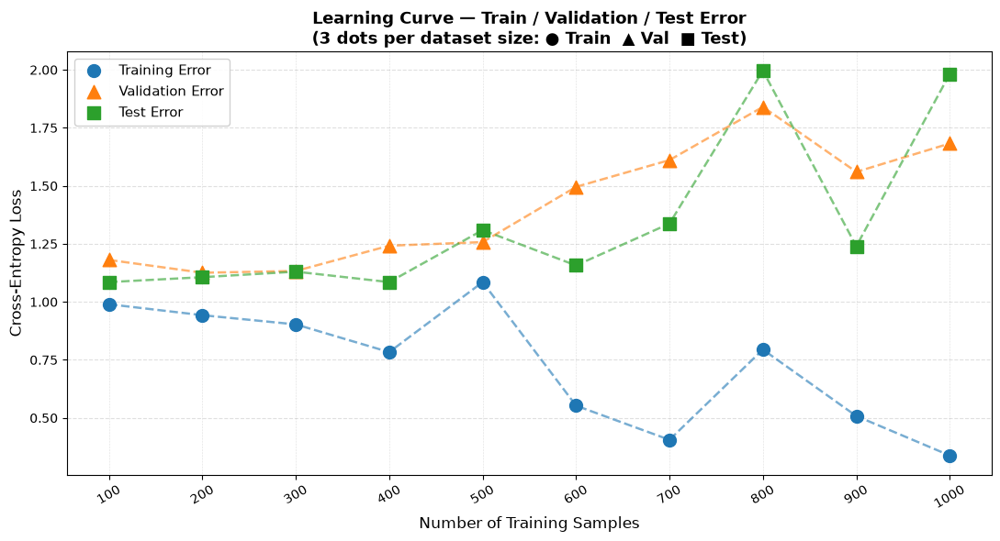

In [45]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(curve_sizes, curve_train, color='#1f77b4', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_val,   color='#ff7f0e', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_test,  color='#2ca02c', linewidth=1.8, linestyle='--', alpha=0.6)

ax.scatter(curve_sizes, curve_train, marker='o', s=100,
           color='#1f77b4', zorder=5, label='Training Error')
ax.scatter(curve_sizes, curve_val,   marker='^', s=110,
           color='#ff7f0e', zorder=5, label='Validation Error')
ax.scatter(curve_sizes, curve_test,  marker='s', s=100,
           color='#2ca02c', zorder=5, label='Test Error')

for s in curve_sizes:
    ax.axvline(s, color='grey', linewidth=0.4, linestyle=':', alpha=0.5)

ax.set_xlabel('Number of Training Samples', fontsize=12)
ax.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax.set_title('Learning Curve — Train / Validation / Test Error\n'
             '(3 dots per dataset size: ● Train  ▲ Val  ■ Test)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.set_xticks(curve_sizes)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
try:
    plt.savefig(OUTPUT_DIR / 'learning_curve.png', dpi=130, bbox_inches='tight')
except OSError as e:
    print(f'  (could not save figure — {e})')
plt.show()

## 15. Full Training History (MLP on Full Train Set)

In [46]:
history_model, history_opt, history_sch = make_model()
h = {'train_loss': [], 'val_loss': [], 'test_loss': [],
     'train_acc':  [], 'val_acc':  [], 'test_acc':  []}

best_acc_ht   = -1.0
best_state_ht = None
patience_ht   = 0

print(f'Training MLP for up to {NUM_EPOCHS} epochs …\n')
for epoch in range(NUM_EPOCHS):
    tr_l, tr_a = train_one_epoch(history_model, train_loader, history_opt)
    vl_l, vl_a, _, _ = evaluate(history_model, val_loader)
    te_l, te_a, _, _ = evaluate(history_model, test_loader)
    history_sch.step()

    for key, val in zip(
        ['train_loss','val_loss','test_loss','train_acc','val_acc','test_acc'],
        [tr_l, vl_l, te_l, tr_a, vl_a, te_a]
    ):
        h[key].append(val)

    print(f'Ep {epoch+1:02d}/{NUM_EPOCHS}  '
          f'Train L={tr_l:.4f} A={tr_a:.4f} | '
          f'Val L={vl_l:.4f} A={vl_a:.4f} | '
          f'Test L={te_l:.4f} A={te_a:.4f}')

    if vl_a > best_acc_ht:
        best_acc_ht   = vl_a
        patience_ht   = 0
        best_state_ht = {k2: v.cpu() for k2, v in history_model.state_dict().items()}
    else:
        patience_ht += 1
        if patience_ht >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}.')
            break

print(f'\nBest validation accuracy: {best_acc_ht:.4f}')

Training MLP for up to 60 epochs …

Ep 01/60  Train L=1.0629 A=0.4622 | Val L=1.1268 A=0.4135 | Test L=1.0645 A=0.3653
Ep 02/60  Train L=0.8486 A=0.5698 | Val L=1.3430 A=0.5215 | Test L=1.3552 A=0.4257
Ep 03/60  Train L=0.5511 A=0.7353 | Val L=1.9322 A=0.3178 | Test L=1.8530 A=0.2477
Ep 04/60  Train L=0.4048 A=0.8187 | Val L=2.3201 A=0.3670 | Test L=2.2162 A=0.3638
Ep 05/60  Train L=0.3486 A=0.8453 | Val L=1.9327 A=0.6242 | Test L=2.1368 A=0.6269
Ep 06/60  Train L=0.2522 A=0.8909 | Val L=2.1790 A=0.5663 | Test L=2.2519 A=0.4721
Ep 07/60  Train L=0.2041 A=0.9133 | Val L=2.9921 A=0.4442 | Test L=3.3528 A=0.2988
Ep 08/60  Train L=0.1942 A=0.9227 | Val L=2.4976 A=0.3494 | Test L=3.1119 A=0.2864
Ep 09/60  Train L=0.1874 A=0.9273 | Val L=2.1182 A=0.4978 | Test L=2.6884 A=0.4087
Ep 10/60  Train L=0.1582 A=0.9370 | Val L=2.6126 A=0.4811 | Test L=2.6494 A=0.3885
Ep 11/60  Train L=0.1640 A=0.9337 | Val L=2.5986 A=0.4021 | Test L=3.0254 A=0.4149
Ep 12/60  Train L=0.1686 A=0.9346 | Val L=2.2248 A=

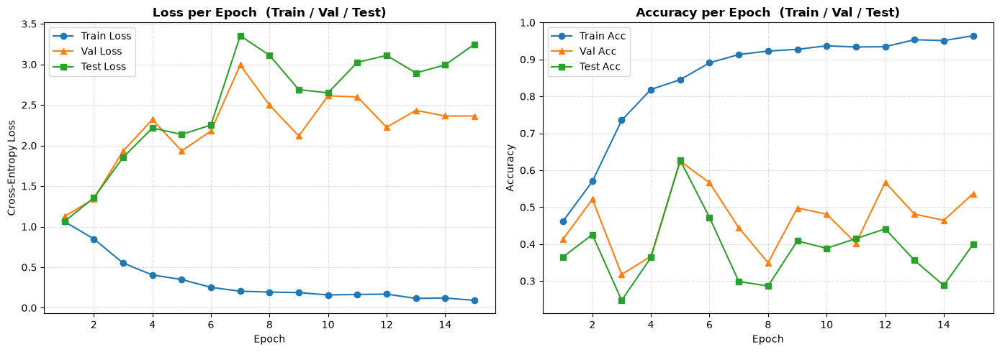

In [47]:
epochs_ran = range(1, len(h['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_ran, h['train_loss'], 'o-', color='#1f77b4', label='Train Loss')
ax1.plot(epochs_ran, h['val_loss'],   '^-', color='#ff7f0e', label='Val Loss')
ax1.plot(epochs_ran, h['test_loss'],  's-', color='#2ca02c', label='Test Loss')
ax1.set_title('Loss per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(); ax1.grid(linestyle='--', alpha=0.4)

ax2.plot(epochs_ran, h['train_acc'], 'o-', color='#1f77b4', label='Train Acc')
ax2.plot(epochs_ran, h['val_acc'],   '^-', color='#ff7f0e', label='Val Acc')
ax2.plot(epochs_ran, h['test_acc'],  's-', color='#2ca02c', label='Test Acc')
ax2.set_title('Accuracy per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend(); ax2.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
try:
    plt.savefig(OUTPUT_DIR / 'training_history.png', dpi=130, bbox_inches='tight')
except OSError as e:
    print(f'  (could not save figure — {e})')
plt.show()

## 16. Save Model

In [48]:
save_path = OUTPUT_DIR / 'rajuk_mlp.pth'

artifact = {
    'model_state_dict' : best_state_ht,
    'class_names'      : CLASS_NAMES,
    'image_size'       : IMAGE_SIZE,
    'input_dim'        : INPUT_DIM,
    'label_source'     : str(source_path),
    'label_column'     : level_col,
    'best_val_acc'     : best_acc_ht,
    'kfold_val_accs'   : fold_val_accs,
    'train_size'       : len(train_dataset),
    'val_size'         : len(val_dataset),
    'test_size'        : len(test_dataset),
    'final_test_acc'   : test_acc,
}

torch.save(artifact, save_path)
print(f'Model saved to  : {save_path}')
print(f'Final test acc  : {test_acc:.4f}')

Model saved to  : d:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Bare_NN\local\rajuk_mlp.pth
Final test acc  : 0.5759


## 17. Sanity Check — Predict on Random Test Samples

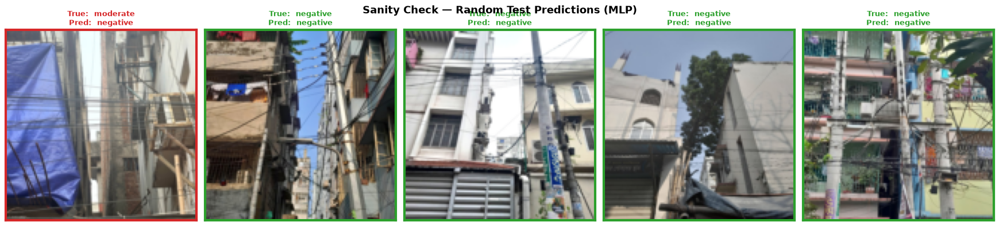

Sanity check complete.


In [49]:
best_model = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
best_model.load_state_dict({k: v.to(device) for k, v in best_state_ht.items()})
best_model.eval()

rng2   = np.random.default_rng(SEED + 1)
sample = rng2.choice(len(test_dataset), size=min(5, len(test_dataset)), replace=False)

fig, axes = plt.subplots(1, len(sample), figsize=(len(sample) * 3.5, 4))
fig.suptitle('Sanity Check — Random Test Predictions (MLP)', fontsize=13, fontweight='bold')

with torch.no_grad():
    for ax, s_idx in zip(axes, sample):
        flat_tensor, true_lbl = test_dataset[int(s_idx)]
        logits   = best_model(flat_tensor.unsqueeze(0).to(device))
        pred_lbl = logits.argmax(1).item()

        # Reshape flat tensor back to image for display
        img_np = flat_tensor.numpy().reshape(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
        img_np = np.clip(img_np, 0, 1)

        ax.imshow(img_np)
        ax.set_xticks([]); ax.set_yticks([])

        colour = '#2ca02c' if pred_lbl == true_lbl else '#d62728'
        ax.set_title(
            f'True:  {CLASS_NAMES[true_lbl]}\nPred:  {CLASS_NAMES[pred_lbl]}',
            fontsize=9, color=colour, fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor(colour); spine.set_linewidth(3)

plt.tight_layout()
try:
    plt.savefig(OUTPUT_DIR / 'sanity_predictions.png', dpi=120, bbox_inches='tight')
except OSError as e:
    print(f'  (could not save figure — {e})')
plt.show()
print('Sanity check complete.')